In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

from PyToF import ClassToF

In [2]:
# Matplotlib rcParams options:

def _default_mpl_opts():
    """
    Return default Matplotlib rcParams options for all plots.

    These settings control visual aspects such as line width, marker size,
    tick style, font size, and figure dimensions. They serve as a base for
    all plotting functions in this module.
    """

    opts = {}

    tick_major_size = 7.0
    tick_minor_size = 4.0
    tick_widths = 1.6

    # Lines and errobar:
    opts["lines.linewidth"] = 3.0
    opts["lines.markersize"] = 4.5
    opts["errorbar.capsize"] = 0.0

    # Axes and margins:
    opts["axes.linewidth"] = 1.6
    opts["axes.labelsize"] = 16
    opts["axes.xmargin"] = 0.0
    opts["axes.ymargin"] = 0.0
    opts["axes.formatter.useoffset"] = False

    # Ticks:
    opts["xtick.labelsize"] = 16
    opts["ytick.labelsize"] = 16
    opts["xtick.direction"] = "in"
    opts["ytick.direction"] = "in"
    opts["xtick.top"] = True
    opts["ytick.right"] = True
    opts["xtick.minor.visible"] = True
    opts["ytick.minor.visible"] = True
    opts["xtick.major.size"] = tick_major_size
    opts["ytick.major.size"] = tick_major_size
    opts["xtick.minor.size"] = tick_minor_size
    opts["ytick.minor.size"] = tick_minor_size
    opts["xtick.major.width"] = tick_widths
    opts["ytick.major.width"] = tick_widths
    opts["xtick.minor.width"] = tick_widths
    opts["ytick.minor.width"] = tick_widths
    opts["xtick.major.pad"] = 7.0
    opts["ytick.major.pad"] = 7.0

    # Legend:
    opts["legend.title_fontsize"] = 14
    opts["legend.fontsize"] = 14

    # Figure properties:
    opts["figure.figsize"] = [6.4, 4.8]
    opts["figure.dpi"] = 300
    opts["font.family"] = "Ubuntu"

    return opts

def _apply_mpl_opts(opts):
    """
    Apply Matplotlib rcParams options from a dictionary.

    opts:   Dictionary of rcParams-style key-value pairs to apply globally.
    """

    for kwd, value in opts.items():
        try:
            plt.rcParams[kwd] = value

        except (KeyError, ValueError):
            continue

mpl_opts = _default_mpl_opts()
_apply_mpl_opts(mpl_opts)

In [3]:
# Data:

N = 2**10
rho_mean = 1326 #kg m^-3
radius = [70e6, 70e6, 70e6, 25e6, 70e6] #m
G = 6.6738480e-11 #SI units
sum_upper_limit = 50

#######

def linear(r, radius):
    x = r/radius
    return 4*rho_mean*(1-x)

def quadratic(r, radius):
    x = r/radius
    return 2.5*rho_mean*(1-x**2)

def polytropic(r, radius):
    x = r/radius
    return np.pi**2/3*rho_mean*np.sin(np.pi*x)/(np.pi*x)

def multi_polytropic1(r, radius):
    x = r/radius
    arr = np.array([
        [1.000, 0.000],
        [0.982, 0.020],
        [0.964, 0.051],
        [0.955, 0.067],
        [0.939, 0.091],
        [0.930, 0.114],
        [0.914, 0.142],
        [0.901, 0.166],
        [0.886, 0.189],
        [0.870, 0.221],
        [0.854, 0.249],
        [0.828, 0.292],
        [0.812, 0.324],
        [0.795, 0.347],
        [0.786, 0.371],
        [0.785, 1.13 ],
        [0.771, 1.26 ],
        [0.759, 1.37 ],
        [0.747, 1.48 ],
        [0.734, 1.59 ],
        [0.720, 1.71 ],
        [0.711, 1.78 ],
        [0.696, 1.90 ],
        [0.685, 1.99 ],
        [0.673, 2.09 ],
        [0.658, 2.20 ],
        [0.638, 2.34 ],
        [0.618, 2.48 ],
        [0.599, 2.62 ],
        [0.589, 2.67 ],
        [0.573, 2.77 ],
        [0.557, 2.87 ],
        [0.542, 2.95 ],
        [0.525, 3.05 ],
        [0.507, 3.14 ],
        [0.492, 3.23 ],
        [0.476, 3.31 ],
        [0.458, 3.40 ],
        [0.440, 3.48 ],
        [0.424, 3.55 ],
        [0.411, 3.60 ],
        [0.390, 3.69 ],
        [0.376, 3.74 ],
        [0.361, 3.80 ],
        [0.350, 3.83 ],
        [0.333, 3.89 ],
        [0.316, 3.93 ],
        [0.295, 3.997],
        [0.283, 4.01 ],
        [0.262, 4.07 ],
        [0.238, 4.13 ],
        [0.217, 4.18 ],
        [0.193, 4.23 ],
        [0.170, 4.28 ],
        [0.151, 4.31 ],
        [0.125, 4.35 ],
        [0.100, 4.38 ],
        [0.0804, 4.40 ],
        [0.0588, 4.40 ],
        [0.0379, 4.41 ],
        [0.000, 4.41 ],
    ])
    return scipy.interpolate.interp1d(arr[:,0], 1000*arr[:,1])(x)

def multi_polytropic2(r, radius):
    x = r/radius
    arr = np.array([
        [1.000,  0.000],
        [0.945,  0.097],
        [0.916,  0.264],
        [0.858,  0.527],
        [0.831,  0.680],
        [0.799,  0.804],
        [0.775,  0.887],
        [0.747,  1.194],
        [0.713,  1.374],
        [0.674,  1.569],
        [0.632,  1.805],
        [0.603,  1.957],
        [0.566,  2.152],
        [0.534,  2.304],
        [0.510,  2.429],
        [0.480,  2.582],
        [0.453,  2.735],
        [0.425,  2.901],
        [0.394,  3.026],
        [0.363,  3.207],
        [0.336,  3.359],
        [0.304,  3.540],
        [0.272,  3.692],
        [0.218,  3.984],
        [0.185,  4.164],
        [0.155,  4.359],
        [0.147,  4.373],
        [0.146, 12.518],
        [0.139, 12.994],
        [0.135, 13.162],
        [0.132, 13.330],
        [0.127, 13.596],
        [0.123, 13.778],
        [0.109, 14.338],
        [0.105, 14.478],
        [0.099, 14.730],
        [0.094, 14.898],
        [0.085, 15.248],
        [0.080, 15.402],
        [0.076, 15.500],
        [0.069, 15.710],
        [0.064, 15.822],
        [0.058, 15.947],
        [0.047, 16.115],
        [0.041, 16.213],
        [0.034, 16.311],
        [0.015, 16.450],
        [0.000, 16.505],
    ])
    return scipy.interpolate.interp1d(arr[:,0], 1000*arr[:,1])(x)

funcs = [linear, quadratic, polytropic, multi_polytropic1, multi_polytropic2]

#######

def g_linear(r, radius):
    x = r/radius
    return 16/3*np.pi*G*rho_mean*radius*x*(1-3*x/4)

def g_quadratic(r, radius):
    x = r/radius
    return 10*np.pi*G*rho_mean*radius*x*(1/3-x**2/5)

def g_polytropic(r, radius):
    x = r/radius
    d_sinc = lambda x: (x*np.cos(x)-np.sin(x))/x**2
    return -4/3*np.pi*G*radius**3*rho_mean*d_sinc(np.pi*x)*np.pi/radius**2

gs = [g_linear, g_quadratic, g_polytropic, None, None]

#######

def T_linear(r, n, g, radius):
    x = r / radius
    P = np.ones(sum_upper_limit)

    for i in range(1, sum_upper_limit):
        k = i - 1
        Delta = (k**2 + (2*n + 1)*k - 4) / (k**2 + (2*n + 3)*k + 2*(n + 1))
        P[i] = P[i-1] * Delta

    denom = (2*n+1) + np.sum( (3/4)**np.arange(1, sum_upper_limit) * (np.arange(1,sum_upper_limit)+2*n+1) * P[1:] )
    C0 = (2*n+1) * g * radius / denom
    Ci = C0 * (3/4)**np.arange(sum_upper_limit) * P

    T = np.zeros_like(x, dtype=float)
    for ii in range(sum_upper_limit):
        T += Ci[ii] * x**(ii + n)

    return T

def T_quadratic(r,n,g, radius):
    x = r / radius
    P = np.ones(sum_upper_limit)

    for i in range(1, sum_upper_limit):
        k = i - 1
        Delta = (2*k**2 + (2*n + 1)*k - 5) / (2*k**2 + (2*n + 5)*k + 2*n + 3)
        P[i] = P[i-1] * Delta

    denom = (2*n+1) + np.sum( (3/5)**np.arange(1, sum_upper_limit) * (2*np.arange(1, sum_upper_limit)+2*n+1) * P[1:] )
    C0 = (2*n+1) *g * radius / denom
    Ci = C0 * (3/5)**np.arange(sum_upper_limit) * P

    T = np.zeros_like(x, dtype=float)
    for ii in range(sum_upper_limit):
        T += Ci[ii] * x**(n + 2*ii)

    return T

def T_polytropic(r,n,g, radius):
    x = r/radius
    return (2*n+1)*radius*g / (np.pi*scipy.special.jv(n-0.5, np.pi)) * x**(-0.5) * scipy.special.jv(n+0.5, np.pi*x)

Ts = [T_linear, T_quadratic, T_polytropic, None, None]

#######

def K_linear(r, n, radius):
    x = r/radius
    P = np.ones(sum_upper_limit)

    for i in range(1, sum_upper_limit):
        k = i - 1
        Delta = (k**2 + (2*n + 1)*k - 4) / (k**2 + (2*n + 3)*k + 2*(n + 1))
        P[i] = P[i-1] * Delta

    denom = (2*n+1) + np.sum( (3/4)**np.arange(1, sum_upper_limit) * (np.arange(1, sum_upper_limit)+2*n+1) * P[1:] )
    series = np.zeros_like(x, dtype=float)

    for ii in range(1, sum_upper_limit):
        series += (3/4)**ii * P[ii] * x**ii

    K = x**n * ( (2*n+1)*(1.0+series)/denom - 1.0 )

    return K

def K_quadratic(r, n, radius):
    x = r/radius
    P = np.ones(sum_upper_limit)

    for i in range(1, sum_upper_limit):
        k = i - 1
        Delta = (2*k**2 + (2*n + 1)*k - 5) / (2*k**2 + (2*n + 5)*k + 2*n + 3)
        P[i] = P[i-1] * Delta

    denom = (2*n+1) + np.sum( (3/5)**np.arange(1, sum_upper_limit) * (2*np.arange(1, sum_upper_limit)+2*n+1) * P[1:] )
    series = np.zeros_like(x, dtype=float)

    for ii in range(1, sum_upper_limit):
        series += (3/5)**ii * P[ii] * x**(2*ii)

    K = x**n * ( (2*n+1)*(1.0+series)/denom - 1.0 )

    return K

def K_polytropic(r,n, radius):
    x = r/radius
    return (2*n+1)*scipy.special.jv(n+0.5, np.pi*x) / (np.pi*x**(0.5)*scipy.special.jv(n-0.5, np.pi)) - x**n

def K_multi_polytropic2(r,n, radius):
    x = r/radius
    arr = np.array([
        [1.000, 0.383],
        [0.993, 0.388],
        [0.982, 0.399],
        [0.955, 0.421],
        [0.935, 0.436],
        [0.912, 0.449],
        [0.885, 0.461],
        [0.860, 0.467],
        [0.831, 0.471],
        [0.792, 0.468],
        [0.744, 0.460],
        [0.709, 0.449],
        [0.674, 0.434],
        [0.638, 0.417],
        [0.604, 0.395],
        [0.557, 0.364],
        [0.527, 0.340],
        [0.499, 0.318],
        [0.475, 0.298],
        [0.452, 0.278],
        [0.420, 0.250],
        [0.392, 0.224],
        [0.353, 0.190],
        [0.321, 0.160],
        [0.295, 0.138],
        [0.268, 0.117],
        [0.247, 0.099],
        [0.220, 0.081],
        [0.184, 0.054],
        [0.166, 0.040],
        [0.149, 0.027],
        [0.143, 0.026],
        [0.108, 0.017],
        [0.061, 0.009],
        [0.026, 0.005],
        [0.000, 0.000],
    ])
    return scipy.interpolate.interp1d(arr[:,0], arr[:,1])(x)

Ks = [K_linear, K_quadratic, K_polytropic, None, K_multi_polytropic2]

#######

bs = [None, None, None, radius[3]*0.785, radius[4]*0.146]

/home/lumo/Code/PyToF_dev/PyToF/AlgoToF.py:539: AccuracyWarning: Reverting to the more stable and less accurate trapezoid rule for integration because S_0, itself proportional to the enclosed mass function, has become non-monotonic. Discontinuities in the density gradient due to jumps in density are likely responsible.
  warn_simpson_fallback(


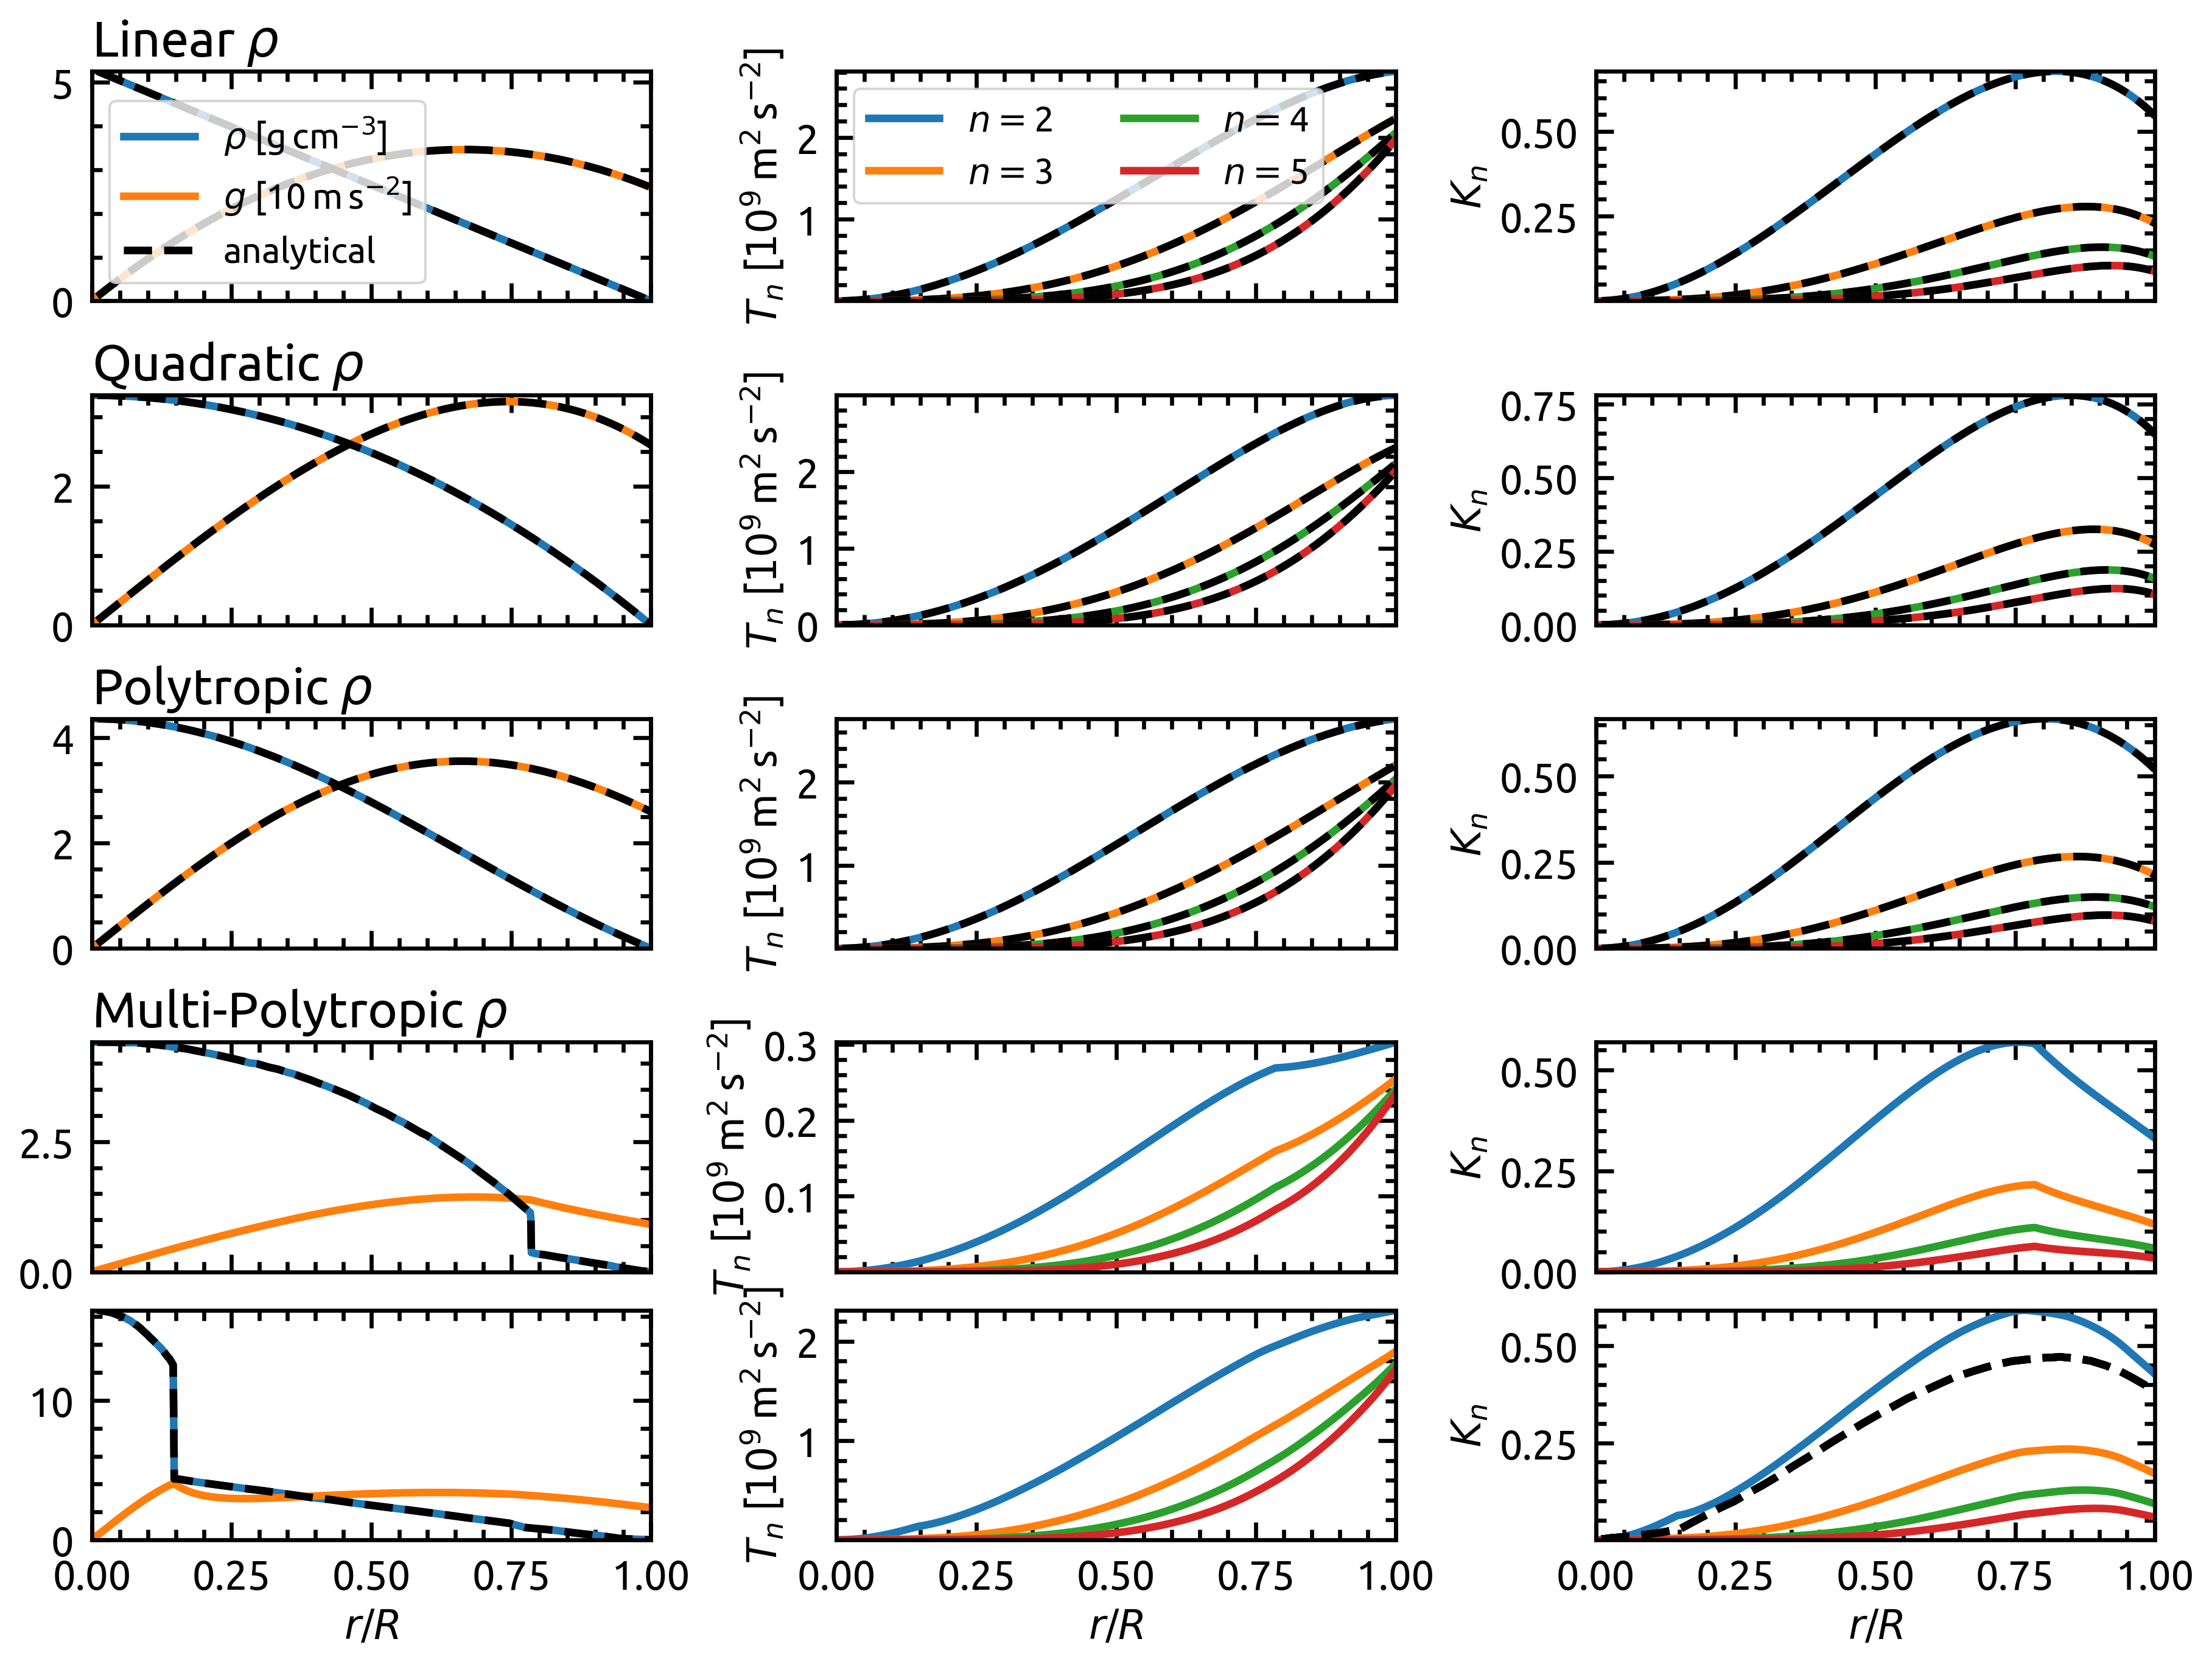

In [4]:
fig, axs = plt.subplots(5, 3, figsize=(12,9), layout='constrained', sharex=True)

for i in range(3):
    axs[4,i].set_xlabel(r'$r/R$')
    axs[4,i].set_xlim((0,1))

for i in range(5):
    axs[i,1].set_ylabel(r'$T_n$ [$10^9\,$m$^{2}\,$s$^{-2}$]')
    axs[i,2].set_ylabel(r'$K_n$')

for i in range(len(funcs)):
    
    radii = radius[i] * np.linspace(0.01, 1, N) #m
    mass = 4 * np.pi * np.trapezoid(funcs[i](radii, radius[i]) * radii**2, radii) # Mass integral (trapezoidal, negative sign due to order of radii)
    
    X = ClassToF.ToF(N=N, M_phys=mass, R_phys=[radius[i], 'mean'], Period=np.inf)
    X.li = radii[::-1]
    X.rhoi = funcs[i](radii[::-1], radius[i])
    X.m_rot_calc = (2 * np.pi / np.inf)**2 * X.li[0]**3 / (G * mass)

    number_of_iterations = X.relax_to_shape()

    X.get_Kn(0)

    axs[i,0].plot(X.li/radius[i], X.rhoi/1000, label=r'$\rho$ [g$\,$cm$^{-3}$]')
    axs[i,0].plot(X.li/radius[i], -np.gradient(X.U, X.li)/10, label=r'$g$ [10$\,$m$\,$s$^{-2}$]')
    axs[i,0].plot(radii/radius[i], funcs[i](radii, radius[i])/1000, 'k--', label='analytical')
    if gs[i] is not None:
        axs[i,0].plot(radii/radius[i], gs[i](radii, radius[i])/10, 'k--')
    
    for n in [2,3,4,5]:
        
        r, T_n, K_n = X.get_Kn(n, bs=bs[i])
        
        axs[i,1].plot(r/radius[i], T_n/1e9, label=r'$n=$'+str(n))
        axs[i,2].plot(r/radius[i], K_n*(r/radius[i])**n, label=r'$n=$'+str(n))

        if gs[i] is not None and Ts[i] is not None:
            T_anal = Ts[i](radii, n, gs[i](radius[i], radius[i]), radius[i])
            axs[i,1].plot(radii/radius[i], T_anal/1e9, 'k--')

        if Ks[i] is not None:
            K_anal = Ks[i](radii, n, radius[i])
            axs[i,2].plot(radii/radius[i], K_anal, 'k--')

axs[0,0].legend()
axs[0,1].legend(ncol=2)

row_labels = [r'Linear $\rho$', r'Quadratic $\rho$', r'Polytropic $\rho$', r'Multi-Polytropic $\rho$']

for i, label in enumerate(row_labels):
    axs[i,0].set_title(label, loc='left', fontsize=20)